# Classification Track — Part B
## 11. MLP Classifier (Neural Network)

**Notes from the algorithm list:** Tune hidden layer sizes and activation.

A Multi-Layer Perceptron is a feed-forward neural network: stacked fully connected layers with non-linear activations, trained by back-propagation, with a softmax output for the 7 classes. Like KNN and SVM it is sensitive to feature scale, which is already handled in notebook `00` (StandardScaler fitted on train only). Early stopping is enabled so the network stops training when validation loss stops improving.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              confusion_matrix, classification_report, roc_auc_score,
                              roc_curve, auc)
from sklearn.preprocessing import label_binarize
import os, time

RANDOM_STATE = 42
sns.set_style("whitegrid")

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")
class_map = pd.read_csv("../data/processed/class_mapping.csv", index_col=0)["class_name"].to_dict()
class_names = [class_map[i] for i in sorted(class_map.keys())]

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Classes:", class_names)

X_train: (1688, 21)  X_test: (423, 21)
Classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


### Model training: baseline (default parameters) vs. tuned (GridSearchCV)

A default-parameter **baseline** is trained first so the improvement from tuning can be documented (Review 2 rubric A3). Both models use the same train split, and both are scored on the same held-out test set.

In [2]:
ALGO_KEY = "mlp"
ALGO_DISPLAY = "MLP Classifier"

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

baseline = MLPClassifier(max_iter=1000, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_acc = accuracy_score(y_test, base_pred)
base_f1 = f1_score(y_test, base_pred, average='weighted')
print(f"Baseline (default params) -> Accuracy: {base_acc:.4f} | Weighted F1: {base_f1:.4f}")

param_grid = {
    'hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.01],
}
grid = GridSearchCV(MLPClassifier(max_iter=1000, early_stopping=True, n_iter_no_change=20,
                                  random_state=RANDOM_STATE),
                    param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV weighted-F1:", round(grid.best_score_, 4))
mlp = grid.best_estimator_

Baseline (default params) -> Accuracy: 0.9574 | Weighted F1: 0.9570


Best params: {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (128, 64)}
Best CV weighted-F1: 0.9424


### Effect of hyperparameters (tuning)

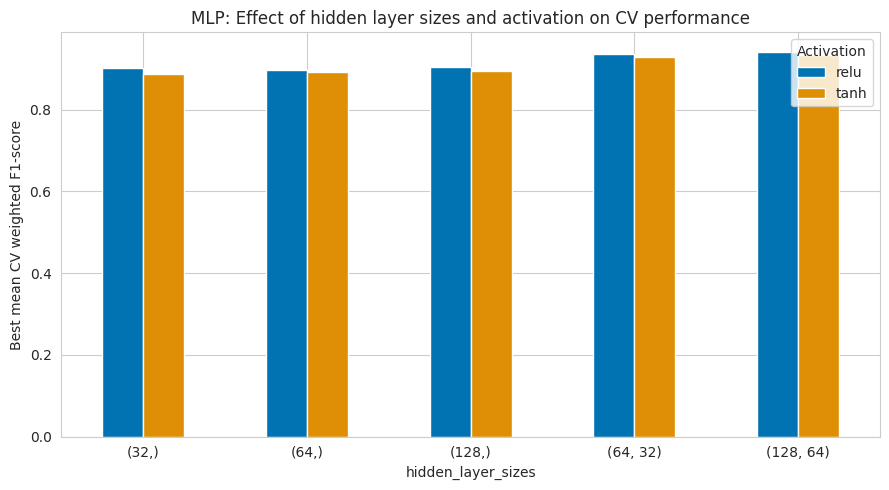

In [3]:
results_df = pd.DataFrame(grid.cv_results_)
results_df['hidden_layer_sizes'] = results_df['param_hidden_layer_sizes'].astype(str)
pivot = results_df.groupby(['hidden_layer_sizes', 'param_activation'])['mean_test_score'].max().unstack()
order_ = [str(s) for s in [(32,), (64,), (128,), (64, 32), (128, 64)]]
pivot = pivot.loc[order_]

pivot.plot(kind='bar', figsize=(9, 5), color=sns.color_palette("colorblind")[:2])
plt.xlabel("hidden_layer_sizes")
plt.ylabel("Best mean CV weighted F1-score")
plt.title("MLP: Effect of hidden layer sizes and activation on CV performance")
plt.xticks(rotation=0)
plt.legend(title="Activation")
plt.tight_layout()
plt.savefig("../results/fig_mlp_tuning.png", bbox_inches="tight")
plt.show()

**Discussion:** more hidden units / layers increase capacity, but with only ~1,700 training rows a very large network can overfit; `alpha` (L2 penalty) counteracts this. `relu` is the usual default, while `tanh` is smoother and sometimes works better on small, standardised tabular data.

### Training loss curve

Shows whether the network converged smoothly (loss decreasing and levelling off).

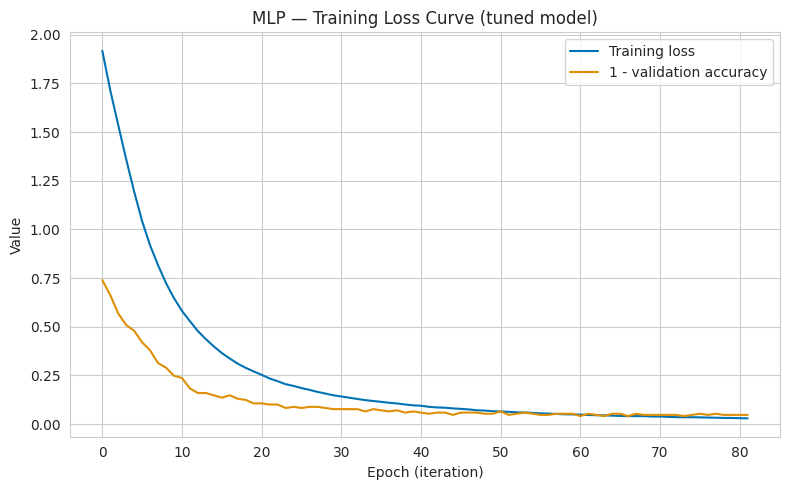

Epochs run: 82


In [4]:
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, color=sns.color_palette("colorblind")[0], label="Training loss")
if getattr(mlp, "validation_scores_", None) is not None:
    plt.plot([1 - s for s in mlp.validation_scores_], color=sns.color_palette("colorblind")[1],
             label="1 - validation accuracy")
plt.xlabel("Epoch (iteration)")
plt.ylabel("Value")
plt.title("MLP — Training Loss Curve (tuned model)")
plt.legend()
plt.tight_layout()
plt.savefig("../results/fig_mlp_loss_curve.png", bbox_inches="tight")
plt.show()
print("Epochs run:", mlp.n_iter_)

### Prediction

Use the tuned model to predict on the held-out test set (`X_test`), which the model has never seen during `.fit()`.

In [5]:
y_pred = mlp.predict(X_test)
y_proba = mlp.predict_proba(X_test)

print("Predictions generated for", len(y_pred), "test samples.")
print("First 10 predicted labels:", [class_map[i] for i in y_pred[:10]])
print("First 10 actual labels   :", [class_map[i] for i in y_test.values[:10]])

Predictions generated for 423 test samples.
First 10 predicted labels: ['Insufficient_Weight', 'Insufficient_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Normal_Weight', 'Obesity_Type_I', 'Overweight_Level_I']
First 10 actual labels   : ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Normal_Weight', 'Obesity_Type_I', 'Overweight_Level_I']


### Evaluation

In [6]:
acc = accuracy_score(y_test, y_pred)
f1_weighted = f1_score(y_test, y_pred, average='weighted')
precision_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average='weighted')

y_test_bin = label_binarize(y_test, classes=sorted(class_map.keys()))
roc_auc_ovr = roc_auc_score(y_test_bin, y_proba, multi_class='ovr', average='weighted')

print(f"Accuracy           : {acc:.4f}")
print(f"Weighted Precision  : {precision_weighted:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Weighted F1-score   : {f1_weighted:.4f}")
print(f"ROC-AUC (OvR, wtd)  : {roc_auc_ovr:.4f}")
print()
print("Full classification report:")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

Accuracy           : 0.9480
Weighted Precision  : 0.9484
Weighted Recall     : 0.9480
Weighted F1-score   : 0.9481
ROC-AUC (OvR, wtd)  : 0.9973

Full classification report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.95      0.96      0.95        54
      Normal_Weight       0.86      0.88      0.87        58
     Obesity_Type_I       0.97      0.97      0.97        70
    Obesity_Type_II       0.98      0.98      0.98        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.90      0.90      0.90        58
Overweight_Level_II       0.96      0.95      0.96        58

           accuracy                           0.95       423
          macro avg       0.95      0.95      0.95       423
       weighted avg       0.95      0.95      0.95       423



### Baseline vs. tuned

In [7]:
print(f"{'Model':<22}{'Accuracy':>10}{'Weighted F1':>14}")
print(f"{'Baseline (default)':<22}{base_acc:>10.4f}{base_f1:>14.4f}")
print(f"{'Tuned (GridSearchCV)':<22}{acc:>10.4f}{f1_weighted:>14.4f}")
print(f"{'Change':<22}{acc-base_acc:>+10.4f}{f1_weighted-base_f1:>+14.4f}")

Model                   Accuracy   Weighted F1
Baseline (default)        0.9574        0.9570
Tuned (GridSearchCV)      0.9480        0.9481
Change                   -0.0095       -0.0089


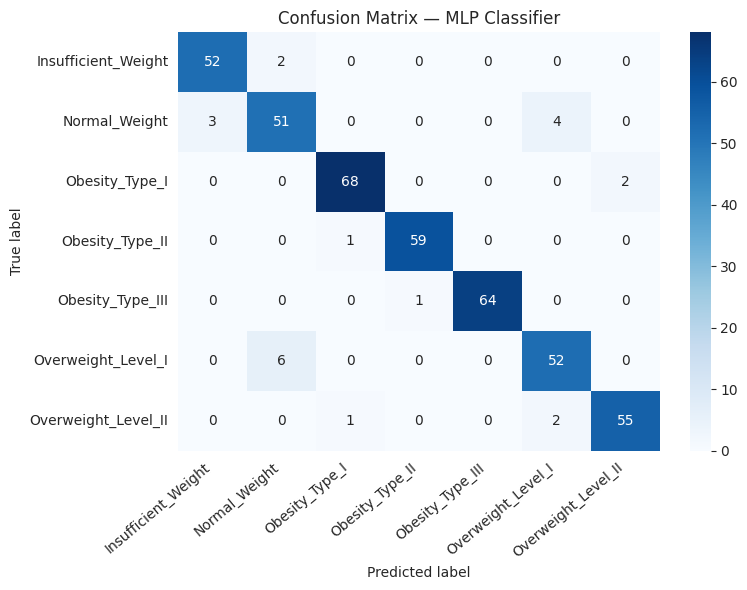

In [8]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Confusion Matrix — {ALGO_DISPLAY}")
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"../results/fig_confusion_matrix_{ALGO_KEY}.png", bbox_inches="tight")
plt.show()

### ROC Curves (One-vs-Rest)

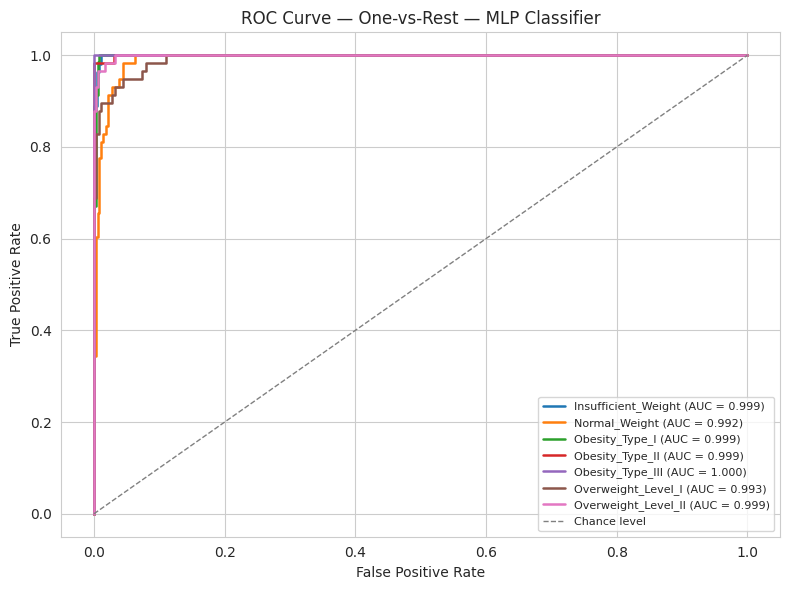

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("tab10", n_colors=len(class_names))

for i, cname in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc_i = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[i], lw=1.8, label=f"{cname} (AUC = {roc_auc_i:.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1, label='Chance level')
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"ROC Curve — One-vs-Rest — {ALGO_DISPLAY}")
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(f"../results/fig_roc_curve_{ALGO_KEY}.png", bbox_inches="tight")
plt.show()

In [10]:
TUNED_MODEL = mlp
# Save the tuned model (guidelines: models/ folder, .pkl via joblib) -- reused by notebook 12 for cross-validation
import joblib
os.makedirs("../models", exist_ok=True)
joblib.dump(TUNED_MODEL, f"../models/{ALGO_KEY}.pkl")

# Log baseline-vs-tuned comparison (feeds Review 2 rubric A3: "improvement in at least one metric documented")
tuning_path = "../results/part_b_tuning_log.csv"
trow = pd.DataFrame([{
    "Algorithm": ALGO_DISPLAY,
    "Baseline_F1_weighted": round(base_f1, 4),
    "Tuned_F1_weighted": round(f1_weighted, 4),
    "Baseline_Accuracy": round(base_acc, 4),
    "Tuned_Accuracy": round(acc, 4),
    "Best_CV_F1": round(grid.best_score_, 4),
    "Best_Params": str(grid.best_params_),
}])
if os.path.exists(tuning_path):
    ex = pd.read_csv(tuning_path)
    ex = ex[ex["Algorithm"] != ALGO_DISPLAY]
    trow = pd.concat([ex, trow], ignore_index=True)
trow.to_csv(tuning_path, index=False)

results_path = "../results/part_b_results.csv"
row = pd.DataFrame([{
    "Algorithm": ALGO_DISPLAY,
    "Accuracy": round(acc, 4),
    "Precision_weighted": round(precision_weighted, 4),
    "Recall_weighted": round(recall_weighted, 4),
    "F1_weighted": round(f1_weighted, 4),
    "ROC_AUC_OvR": round(roc_auc_ovr, 4),
}])

if os.path.exists(results_path):
    existing = pd.read_csv(results_path)
    existing = existing[existing["Algorithm"] != ALGO_DISPLAY]
    combined = pd.concat([existing, row], ignore_index=True)
else:
    combined = row

combined.to_csv(results_path, index=False)
print(f"Logged result for '{ALGO_DISPLAY}' to part_b_results.csv:")
row

Logged result for 'MLP Classifier' to part_b_results.csv:


,Algorithm,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OvR
0,MLP Classifier,0.948,0.9484,0.948,0.9481,0.9973
